# CSCI323 Group Project: Sentiment Analysis (Local / Deduplicated Edition v5)

### Key Features in v5:
1. **No Google Drive Mount Required:** Runs 100% locally in `./sentiment_project_workspace`.
2. **Strict Deduplication (Zero Train-Test Leakage):** Removes duplicate cleaned tweets (`drop_duplicates(subset=['clean_text'])`) prior to class balancing and splitting.
3. **Hardware Acceleration:** Automatically detects Apple Silicon (`mps`), NVIDIA GPU (`cuda`), or `cpu`.
4. **Class-Balanced Dataset (`BALANCE_MODE` in Cell 2):** Balances Negative, Neutral, and Positive tweets to an exact **1:1:1 ratio**.
5. **3 Meaningfully Different Methods + Hybrid Ensemble:**
   - **Method 1 (Established Baseline):** Optimized Naïve Bayes (`MultinomialNB` / `ComplementNB`) with Log-Odds interpretability.
   - **Method 2 (Proposed Neural Design):** Custom Self-Attention BiLSTM (`AttentionBiLSTMClassifier`).
   - **Method 3 (Literature Method):** Pre-Trained Transformer (`DistilBERT`, Devlin et al., 2019, DOI: `10.18653/v1/N19-1423`).

---

## Cell 1: Environment & Local Directory Setup
*Installs required packages (if missing) and sets up `./sentiment_project_workspace`.*

In [ ]:
%pip install -q datasets transformers accelerate statsmodels scikit-learn pandas numpy matplotlib seaborn torch scipy

import os

PROJECT_DIR = os.path.abspath("./sentiment_project_workspace")
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)
print(f"Local working directory set to: {os.getcwd()}")

Local working directory set to: /content/sentiment_project_workspace


## Cell 2: Module (a) — Data Preparation, Deduplication, Class Balancing & Train/Val/Test Split
*Strips duplicate tweets to prevent data leakage, balances classes to an exact **1:1:1 ratio**, and saves `train.csv`, `val.csv`, and `test.csv` locally.*

README.md:   0%|          | 0.00/3.75k [00:00<?, ?B/s]

Tweets.csv: reconstructing file:   0%|          |  0.00B / 3.42MB            

Tweets.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/14640 [00:00<?, ? examples/s]

Removed 427 short/duplicate tweets to prevent train-test data leakage. Unique rows remaining: 14213

Mode: all_splits
Saved local splits! Train: 4630 | Val: 992 | Test: 993

Training Set Class Distribution (1:1:1 Balanced):
sentiment
negative    1544
positive    1543
neutral     1543
Name: count, dtype: int64


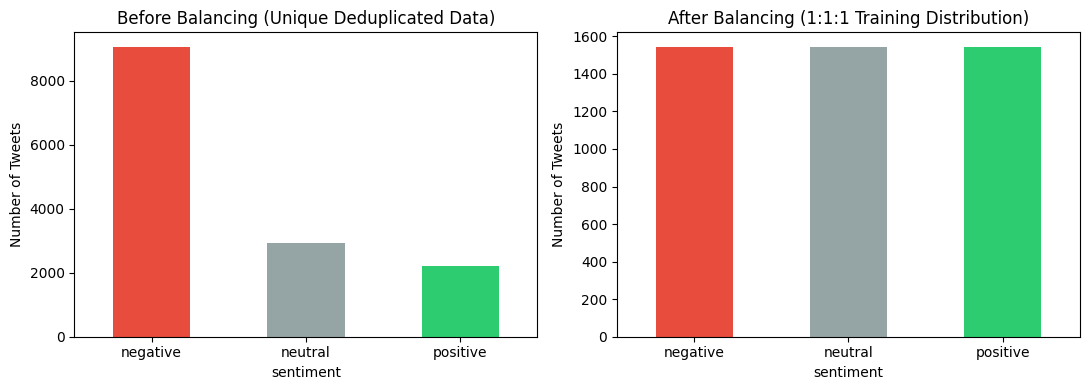

In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

# 'all_splits' = Undersamples entire dataset so Train, Val, and Test all have exact 1:1:1 class balance
# 'train_only' = Splits first, then balances ONLY the Training set (1:1:1)
BALANCE_MODE = 'all_splits'

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"[^a-zA-Z0-9\s!?']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def balance_dataframe(input_df, method='undersample'):
    """Balances Negative (0), Neutral (1), and Positive (2) to exact 1:1:1 counts."""
    counts = input_df['label'].value_counts()
    target_n = counts.min() if method == 'undersample' else counts.max()
    replace_flag = False if method == 'undersample' else True

    balanced_parts = []
    for lbl in [0, 1, 2]:
        subset = input_df[input_df['label'] == lbl]
        resampled = resample(subset, replace=replace_flag, n_samples=target_n, random_state=42)
        balanced_parts.append(resampled)

    return pd.concat(balanced_parts).sample(frac=1.0, random_state=42).reset_index(drop=True)

print("Downloading dataset...")
ds = load_dataset("osanseviero/twitter-airline-sentiment", split="train")
df = pd.DataFrame(ds)[['text', 'airline_sentiment']].rename(
    columns={'airline_sentiment': 'sentiment'}
)

label_map = {'negative': 0, 'neutral': 1, 'positive': 2}
df['label'] = df['sentiment'].map(label_map)
df['clean_text'] = df['text'].apply(clean_text)

raw_len = len(df)
df = df[df['clean_text'].str.len() > 2]
df = df.drop_duplicates(subset=['clean_text']).reset_index(drop=True)
print(f"Removed {raw_len - len(df)} short/duplicate tweets to prevent train-test data leakage. Unique rows remaining: {len(df)}")

orig_counts = df['sentiment'].value_counts()

if BALANCE_MODE == 'all_splits':
    df_balanced = balance_dataframe(df, method='undersample')
    train_df, temp_df = train_test_split(
        df_balanced, test_size=0.30, random_state=42, stratify=df_balanced['label']
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, random_state=42, stratify=temp_df['label']
    )
else:
    train_raw, temp_df = train_test_split(
        df, test_size=0.30, random_state=42, stratify=df['label']
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, random_state=42, stratify=temp_df['label']
    )
    train_df = balance_dataframe(train_raw, method='undersample')

train_df.to_csv("train.csv", index=False)
val_df.to_csv("val.csv", index=False)
test_df.to_csv("test.csv", index=False)

print(f"\nMode: {BALANCE_MODE}")
print(f"Saved local splits! Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("\nTraining Set Class Distribution (1:1:1 Balanced):")
print(train_df['sentiment'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
orig_counts[['negative', 'neutral', 'positive']].plot(kind='bar', ax=axes[0], color=['#e74c3c', '#95a5a6', '#2ecc71'], rot=0)
axes[0].set_title("Before Balancing (Unique Deduplicated Data)")
axes[0].set_ylabel("Number of Tweets")

train_df['sentiment'].value_counts()[['negative', 'neutral', 'positive']].plot(kind='bar', ax=axes[1], color=['#e74c3c', '#95a5a6', '#2ecc71'], rot=0)
axes[1].set_title("After Balancing (1:1:1 Training Distribution)")
axes[1].set_ylabel("Number of Tweets")

plt.tight_layout()
plt.savefig("class_balance_comparison.png", dpi=300)
plt.show()

## Cell 3: Method 1 (Established Baseline) — Optimized Naïve Bayes + Log-Odds Interpretability
*Tunes hyperparameters on the validation set and extracts top predictive N-grams per class.*

In [ ]:
import time
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import classification_report, accuracy_score, f1_score

train_df = pd.read_csv("train.csv").dropna(subset=['clean_text'])
val_df = pd.read_csv("val.csv").dropna(subset=['clean_text'])
test_df = pd.read_csv("test.csv").fillna({'clean_text': ''})

X_train_val = pd.concat([train_df['clean_text'], val_df['clean_text']], ignore_index=True)
y_train_val = pd.concat([train_df['label'], val_df['label']], ignore_index=True)
split_index = [-1] * len(train_df) + [0] * len(val_df)
pds = PredefinedSplit(test_fold=split_index)

pipeline = Pipeline([
    ('vect', TfidfVectorizer()),
    ('clf', MultinomialNB())
])

param_grid = {
    'vect': [CountVectorizer(), TfidfVectorizer()],
    'vect__ngram_range': [(1, 1), (1, 2)],
    'vect__max_features': [5000, 10000, None],
    'clf': [MultinomialNB(), ComplementNB()],
    'clf__alpha': [0.01, 0.1, 0.5, 1.0, 2.0]
}

start_t = time.time()
grid_search = GridSearchCV(pipeline, param_grid, cv=pds, scoring='f1_macro', n_jobs=-1, verbose=1)
grid_search.fit(X_train_val, y_train_val)
nb_train_time = time.time() - start_t

print(f"\nBest Validation Macro-F1: {grid_search.best_score_:.4f} (Time: {nb_train_time:.2f}s)")
print("Best Hyperparameters:", grid_search.best_params_)

best_nb = grid_search.best_estimator_
best_nb.fit(train_df['clean_text'], train_df['label'])

val_probs_nb = best_nb.predict_proba(val_df['clean_text'])
test_probs_nb = best_nb.predict_proba(test_df['clean_text'])
test_preds = np.argmax(test_probs_nb, axis=1)

print("\n--- Method 1: Naive Bayes Test Set Evaluation ---")
print(f"Test Accuracy: {accuracy_score(test_df['label'], test_preds):.4f}")
print(f"Test Macro-F1: {f1_score(test_df['label'], test_preds, average='macro'):.4f}")
print(classification_report(test_df['label'], test_preds, target_names=['Negative', 'Neutral', 'Positive']))

# Rank n-grams by smoothed log-count ratio, one class vs the rest (Wang & Manning, 2012, Eq. 2).
# ComplementNB's feature_log_prob_ ties for every n-gram unseen outside a class, so it can't be ranked directly.
vect, clf = best_nb.named_steps['vect'], best_nb.named_steps['clf']
feature_names = np.array(vect.get_feature_names_out())
doc_freq = np.asarray((vect.transform(train_df['clean_text']) > 0).sum(axis=0)).ravel()
print("--- Mathematical Analysis: Top 8 Predictive N-Grams per Class (Log-Count Ratio, min 5 tweets) ---")
for i, label_name in enumerate(['Negative', 'Neutral', 'Positive']):
    p = clf.feature_count_[i] + clf.alpha
    q = clf.feature_count_.sum(axis=0) - clf.feature_count_[i] + clf.alpha
    log_ratio = np.log(p / p.sum()) - np.log(q / q.sum())
    log_ratio[doc_freq < 5] = -np.inf
    top_idx = np.argsort(log_ratio)[-8:][::-1]
    print(f"{label_name}: {', '.join(feature_names[top_idx])}")

np.save("val_probs_nb.npy", val_probs_nb)
np.save("test_probs_nb.npy", test_probs_nb)
test_df['pred_nb'] = test_preds
test_df[['text', 'label', 'pred_nb']].to_csv("preds_nb.csv", index=False)

## Cell 4: Method 2 (Group Proposed Neural Design) — BiLSTM with Custom Self-Attention Pooling
*Automatically detects Apple Silicon (`mps`), NVIDIA (`cuda`), or `cpu`.*

In [ ]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
from collections import Counter
from sklearn.metrics import classification_report, accuracy_score, f1_score

torch.manual_seed(42)
device = torch.device(
    "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
)
print(f"Training Attention-BiLSTM on device: {device}")

train_df = pd.read_csv("train.csv").fillna({'clean_text': ''})
val_df = pd.read_csv("val.csv").fillna({'clean_text': ''})
test_df = pd.read_csv("test.csv").fillna({'clean_text': ''})

word_counts = Counter()
for text in train_df['clean_text']:
    word_counts.update(str(text).split())

vocab = {"<PAD>": 0, "<UNK>": 1}
for word, count in word_counts.most_common(10000):
    vocab[word] = len(vocab)

def encode_text(text, max_len=50):
    tokens = str(text).split()[:max_len]
    ids = [vocab.get(t, 1) for t in tokens]
    return ids + [0] * (max_len - len(ids))

class SentimentDataset(Dataset):
    def __init__(self, df):
        self.X = torch.tensor([encode_text(t) for t in df['clean_text']], dtype=torch.long)
        self.y = torch.tensor(df['label'].values, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(SentimentDataset(train_df), batch_size=64, shuffle=True)
val_loader = DataLoader(SentimentDataset(val_df), batch_size=64)
test_loader = DataLoader(SentimentDataset(test_df), batch_size=64)

class AttentionBiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, num_classes=3, dropout=0.4):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=2, bidirectional=True, batch_first=True, dropout=dropout)
        self.attention_weights = nn.Linear(hidden_dim * 2, 1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        mask = (x != 0).unsqueeze(-1)
        embedded = self.dropout(self.embedding(x))
        lstm_out, _ = self.lstm(embedded)

        attn_scores = self.attention_weights(torch.tanh(lstm_out))
        attn_scores = attn_scores.masked_fill(~mask, -1e9)
        attn_weights = F.softmax(attn_scores, dim=1)

        context_vector = torch.sum(attn_weights * lstm_out, dim=1)
        return self.fc(self.dropout(context_vector))

model = AttentionBiLSTMClassifier(len(vocab)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

start_t = time.time()
best_val_f1 = 0.0
for epoch in range(1, 10):
    model.train()
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()

    model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            logits = model(X_batch.to(device))
            val_preds.extend(torch.argmax(logits, dim=1).cpu().numpy())
            val_targets.extend(y_batch.numpy())

    val_f1 = f1_score(val_targets, val_preds, average='macro')
    print(f"Epoch {epoch:02d} | Val Macro-F1: {val_f1:.4f}")
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), "best_bilstm.pt")

bilstm_train_time = time.time() - start_t
model.load_state_dict(torch.load("best_bilstm.pt", weights_only=True))
model.eval()

def get_bilstm_probs(loader):
    probs_list = []
    with torch.no_grad():
        for X_batch, _ in loader:
            logits = model(X_batch.to(device))
            probs_list.append(F.softmax(logits, dim=1).cpu().numpy())
    return np.vstack(probs_list)

val_probs_bilstm = get_bilstm_probs(val_loader)
test_probs_bilstm = get_bilstm_probs(test_loader)
test_preds = np.argmax(test_probs_bilstm, axis=1)

print(f"\n--- Method 2: Attention-BiLSTM Test Set Evaluation (Train Time: {bilstm_train_time:.2f}s) ---")
print(f"Test Accuracy: {accuracy_score(test_df['label'], test_preds):.4f}")
print(f"Test Macro-F1: {f1_score(test_df['label'], test_preds, average='macro'):.4f}")
print(classification_report(test_df['label'], test_preds, target_names=['Negative', 'Neutral', 'Positive']))

np.save("val_probs_bilstm.npy", val_probs_bilstm)
np.save("test_probs_bilstm.npy", test_probs_bilstm)
test_df['pred_bilstm'] = test_preds
test_df[['text', 'label', 'pred_bilstm']].to_csv("preds_bilstm.csv", index=False)

Training Attention-BiLSTM on device: cuda
Epoch 01 | Val Macro-F1: 0.6100
Epoch 02 | Val Macro-F1: 0.6605
Epoch 03 | Val Macro-F1: 0.6586
Epoch 04 | Val Macro-F1: 0.6697
Epoch 05 | Val Macro-F1: 0.6738
Epoch 06 | Val Macro-F1: 0.6814
Epoch 07 | Val Macro-F1: 0.6760
Epoch 08 | Val Macro-F1: 0.6708
Epoch 09 | Val Macro-F1: 0.6908

--- Method 2: Attention-BiLSTM Test Set Evaluation (Train Time: 11.43s) ---
Test Accuracy: 0.7090
Test Macro-F1: 0.7096
              precision    recall  f1-score   support

    Negative       0.76      0.68      0.72       331
     Neutral       0.64      0.75      0.69       331
    Positive       0.74      0.70      0.72       331

    accuracy                           0.71       993
   macro avg       0.71      0.71      0.71       993
weighted avg       0.71      0.71      0.71       993



## Cell 5: Method 3 (Research Literature Method) — Pre-Trained Transformer (`DistilBERT`)
*Saves checkpoints to `./distilbert_checkpoints` locally.*

In [ ]:
import time
import torch
import numpy as np
import pandas as pd
from scipy.special import softmax
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from sklearn.metrics import accuracy_score, f1_score, classification_report

MODEL_NAME = "distilbert-base-uncased"

train_df = pd.read_csv("train.csv")[['text', 'label']]
val_df = pd.read_csv("val.csv")[['text', 'label']]
test_df = pd.read_csv("test.csv")[['text', 'label']]

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_fn(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=64)

train_ds = Dataset.from_pandas(train_df).map(tokenize_fn, batched=True)
val_ds = Dataset.from_pandas(val_df).map(tokenize_fn, batched=True)
test_ds = Dataset.from_pandas(test_df).map(tokenize_fn, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro")
    }

training_args = TrainingArguments(
    output_dir="./distilbert_checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    weight_decay=0.01,
    fp16=torch.cuda.is_available(),
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    report_to="none",
    logging_steps=50
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics
)

start_t = time.time()
trainer.train()
bert_train_time = time.time() - start_t

val_out = trainer.predict(val_ds)
test_out = trainer.predict(test_ds)

val_probs_bert = softmax(val_out.predictions, axis=-1)
test_probs_bert = softmax(test_out.predictions, axis=-1)
test_preds = np.argmax(test_probs_bert, axis=-1)

print(f"\n--- Method 3: DistilBERT Test Set Evaluation (Train Time: {bert_train_time:.2f}s) ---")
print(f"Test Accuracy: {accuracy_score(test_df['label'], test_preds):.4f}")
print(f"Test Macro-F1: {f1_score(test_df['label'], test_preds, average='macro'):.4f}")
print(classification_report(test_df['label'], test_preds, target_names=['Negative', 'Neutral', 'Positive']))

np.save("val_probs_bert.npy", val_probs_bert)
np.save("test_probs_bert.npy", test_probs_bert)
test_df['pred_distilbert'] = test_preds
test_df[['text', 'label', 'pred_distilbert']].to_csv("preds_distilbert.csv", index=False)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/4630 [00:00<?, ? examples/s]

Map:   0%|          | 0/992 [00:00<?, ? examples/s]

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


--- Method 3: DistilBERT Test Set Evaluation (Train Time: 56.14s) ---
Test Accuracy: 0.8147
Test Macro-F1: 0.8156
              precision    recall  f1-score   support

    Negative       0.87      0.82      0.84       331
     Neutral       0.74      0.80      0.77       331
    Positive       0.84      0.83      0.83       331

    accuracy                           0.81       993
   macro avg       0.82      0.81      0.82       993
weighted avg       0.82      0.81      0.82       993



## Cell 6: Group's Proposed Hybrid Solution & Systematic Evaluation (Module c)
*Combines all 3 paradigms into a Validation-Optimized Probability Ensemble, runs McNemar's test, analyzes performance by Tweet Length, and plots Confusion Matrices.*

Optimal Hybrid Ensemble Weights (NB, Attn-BiLSTM, DistilBERT): (np.float64(0.05), np.float64(0.3), np.float64(0.65)) | Val Macro-F1: 0.7944

=== SYSTEMATIC MODEL COMPARISON TABLE (DEDUPLICATED & CLASS-BALANCED) ===


,Method,Accuracy,Macro Precision,Macro Recall,Macro F1
0,1. Naive Bayes (Established),0.7492,0.7532,0.7492,0.7456
1,2. Attn-BiLSTM (Proposed Neural),0.7090,0.7146,0.7090,0.7096
2,3. DistilBERT (Literature),0.8147,0.8178,0.8147,0.8156
3,4. Hybrid Ensemble (Proposed Fusion),0.8218,0.8238,0.8218,0.8223



=== STATISTICAL SIGNIFICANCE ANALYSIS (McNemar's Test) ===
McNemar's Test (1. Naive Bayes (Established) vs 2. Attn-BiLSTM (Proposed Neural)): chi2 = 6.56, p-value = 1.0453e-02
McNemar's Test (1. Naive Bayes (Established) vs 3. DistilBERT (Literature)): chi2 = 19.60, p-value = 9.5565e-06
McNemar's Test (2. Attn-BiLSTM (Proposed Neural) vs 3. DistilBERT (Literature)): chi2 = 47.23, p-value = 6.3080e-12

=== THEORETICAL BEHAVIOR ANALYSIS: MACRO-F1 BY SENTENCE LENGTH ===


,Tweet Length,Samples,1. Naive Bayes (Established),2. Attn-BiLSTM (Proposed Neural),3. DistilBERT (Literature)
0,Short (<=10 words),235,0.6798,0.7232,0.7772
1,Medium (11-20 words),440,0.7579,0.6939,0.8092
2,Long (>20 words),318,0.7196,0.6443,0.8044


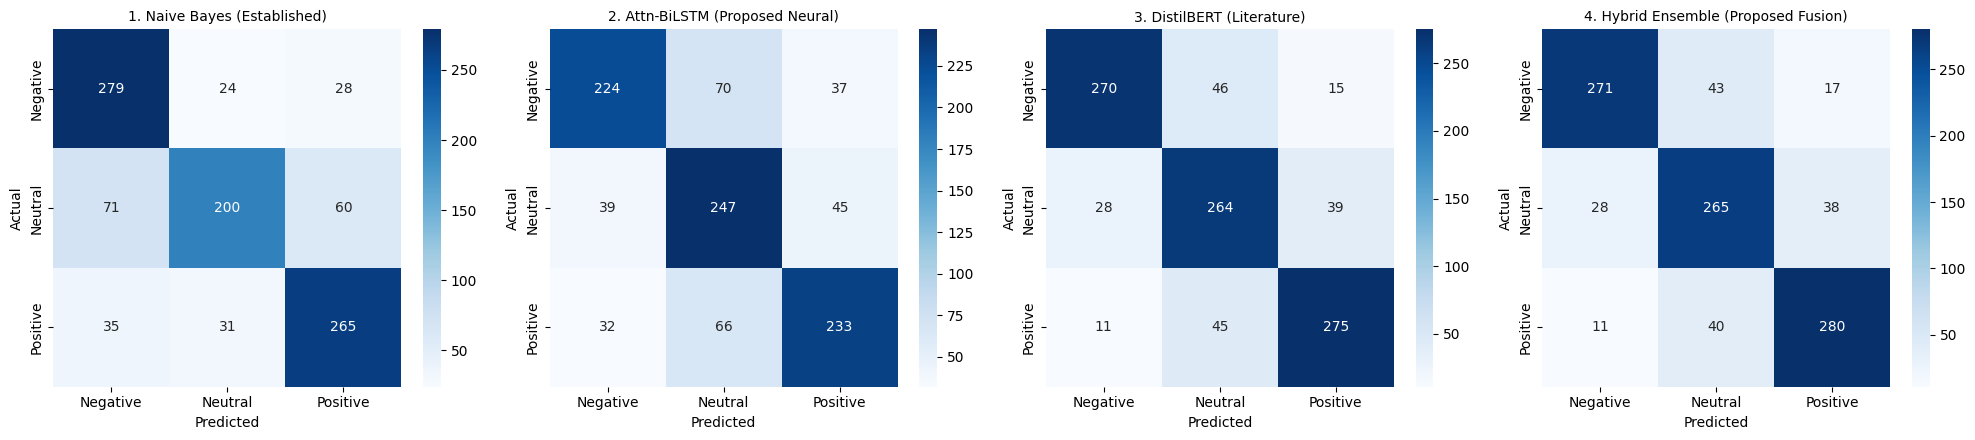

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from statsmodels.stats.contingency_tables import mcnemar

val_df = pd.read_csv("val.csv")
test_df = pd.read_csv("test.csv")

val_nb = np.load("val_probs_nb.npy")
val_bilstm = np.load("val_probs_bilstm.npy")
val_bert = np.load("val_probs_bert.npy")

test_nb = np.load("test_probs_nb.npy")
test_bilstm = np.load("test_probs_bilstm.npy")
test_bert = np.load("test_probs_bert.npy")

# 1. Optimize Hybrid Ensemble Weights on Validation Set
best_weights = (0.2, 0.2, 0.6)
best_val_f1 = 0.0
for w1 in np.linspace(0.05, 0.4, 8):
    for w2 in np.linspace(0.05, 0.4, 8):
        w3 = 1.0 - w1 - w2
        if w3 < 0:
            continue
        blend_val = w1 * val_nb + w2 * val_bilstm + w3 * val_bert
        score = f1_score(val_df['label'], np.argmax(blend_val, axis=1), average='macro')
        if score > best_val_f1:
            best_val_f1 = score
            best_weights = (round(w1, 2), round(w2, 2), round(w3, 2))

w1, w2, w3 = best_weights
print(f"Optimal Hybrid Ensemble Weights (NB, Attn-BiLSTM, DistilBERT): {best_weights} | Val Macro-F1: {best_val_f1:.4f}")
test_ensemble_preds = np.argmax(w1 * test_nb + w2 * test_bilstm + w3 * test_bert, axis=1)

# 2. Compile Master Predictions DataFrame
df = pd.DataFrame({
    'text': test_df['text'],
    'true': test_df['label'],
    '1. Naive Bayes (Established)': np.argmax(test_nb, axis=1),
    '2. Attn-BiLSTM (Proposed Neural)': np.argmax(test_bilstm, axis=1),
    '3. DistilBERT (Literature)': np.argmax(test_bert, axis=1),
    '4. Hybrid Ensemble (Proposed Fusion)': test_ensemble_preds
})

models = [
    '1. Naive Bayes (Established)',
    '2. Attn-BiLSTM (Proposed Neural)',
    '3. DistilBERT (Literature)',
    '4. Hybrid Ensemble (Proposed Fusion)'
]
class_names = ['Negative', 'Neutral', 'Positive']

results = []
for m in models:
    results.append({
        'Method': m,
        'Accuracy': round(accuracy_score(df['true'], df[m]), 4),
        'Macro Precision': round(precision_score(df['true'], df[m], average='macro'), 4),
        'Macro Recall': round(recall_score(df['true'], df[m], average='macro'), 4),
        'Macro F1': round(f1_score(df['true'], df[m], average='macro'), 4)
    })
summary_df = pd.DataFrame(results)
print("\n=== SYSTEMATIC MODEL COMPARISON TABLE (DEDUPLICATED & CLASS-BALANCED) ===")
display(summary_df)

# 3. McNemar's Statistical Significance Test
def run_mcnemar(m1_name, m2_name):
    c1 = (df[m1_name] == df['true'])
    c2 = (df[m2_name] == df['true'])
    table = [[np.sum(c1 & c2), np.sum(c1 & ~c2)],
             [np.sum(~c1 & c2), np.sum(~c1 & ~c2)]]
    res = mcnemar(table, exact=False, correction=True)
    print(f"McNemar's Test ({m1_name} vs {m2_name}): chi2 = {res.statistic:.2f}, p-value = {res.pvalue:.4e}")

print("\n=== STATISTICAL SIGNIFICANCE ANALYSIS (McNemar's Test) ===")
run_mcnemar('1. Naive Bayes (Established)', '2. Attn-BiLSTM (Proposed Neural)')
run_mcnemar('1. Naive Bayes (Established)', '3. DistilBERT (Literature)')
run_mcnemar('2. Attn-BiLSTM (Proposed Neural)', '3. DistilBERT (Literature)')

# 4. Behavior Analysis: Macro-F1 by Tweet Word Length
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))
df['length_bucket'] = pd.cut(df['word_count'], bins=[0, 10, 20, 100], labels=['Short (<=10 words)', 'Medium (11-20 words)', 'Long (>20 words)'])

len_analysis = []
for bucket in ['Short (<=10 words)', 'Medium (11-20 words)', 'Long (>20 words)']:
    sub = df[df['length_bucket'] == bucket]
    row = {'Tweet Length': bucket, 'Samples': len(sub)}
    for m in models[:3]:
        row[m] = round(f1_score(sub['true'], sub[m], average='macro'), 4)
    len_analysis.append(row)

print("\n=== THEORETICAL BEHAVIOR ANALYSIS: MACRO-F1 BY SENTENCE LENGTH ===")
display(pd.DataFrame(len_analysis))

# 5. Plot Confusion Matrices
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, m in zip(axes, models):
    cm = confusion_matrix(df['true'], df[m])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(m, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrices_comparison_v5.png", dpi=300)
plt.show()